<a target="_blank" href="https://colab.research.google.com/github/LSSTC-DSFP/Session-27/blob/main/Day4/MLForTimeSeries.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

# Machine Learning for Time-Series Data: Classifying Rubin-like Light Curves

***

Helen Qu (Flatiron Institute | CCA)
19 Nov 2026

In Lecture IX we sorted machine-learning approaches for time-series classification into two broad families:

1. **Feature-based**: summarise each light curve with a fixed-length vector of (mostly hand-designed) features, then train a "classical" classifier, such as an ensemble of decision trees.
2. **Representation learning**: give a neural network a lightly processed version of the data, and let the network learn its own features.

In this notebook you will build a simplified version of one well-known example from each family, and apply both to the same data set:

* **avocado** ([Boone 2019](https://ui.adsabs.harvard.edu/abs/2019AJ....158..257B/abstract)): 2D Gaussian-process (GP) fit $\rightarrow$ features $\rightarrow$ gradient-boosted decision trees.
* **SCONE** ([Qu et al. 2021](https://ui.adsabs.harvard.edu/abs/2021AJ....162...67Q/abstract)): 2D GP fit $\rightarrow$ wavelength $\times$ time "heatmap" $\rightarrow$ convolutional neural network (CNN).

Both methods start from the same GP model, which builds directly on the GP material from Days 2 and 3.

**Learning Objectives**

By the end of this notebook you should be able to:

1. Describe the properties of survey light curves (irregular sampling, gaps, multiple bands, heteroskedastic noise, class imbalance) that make them hard inputs for standard ML algorithms.
2. Use a 2D (time $\times$ wavelength) GP to turn an irregular multi-band light curve into a regular representation.
3. Build a feature-based classifier with gradient-boosted trees, and evaluate it with metrics that are appropriate for imbalanced classes.
4. Build and train a CNN on GP "heatmaps", and compare it with the feature-based classifier.

*Note on compute* – Everything in this notebook runs on a CPU in a few minutes. If you are in Colab, a GPU makes Problem 4 faster (*Runtime* $\rightarrow$ *Change runtime type* $\rightarrow$ *T4 GPU*), but a GPU is not necessary.

*Note on the data* – The first cells download about 80 MB from [Hugging Face](https://huggingface.co/datasets/helenqu/astro-time-series). In Colab you may see a warning that `HF_TOKEN` does not exist. You can ignore this warning: the data set is public.

In [2]:
import os
import time
import copy
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.linalg import cho_factor, cho_solve, solve_triangular, LinAlgError
from scipy.optimize import minimize
from astropy.timeseries import LombScargle
from joblib import Parallel, delayed
from huggingface_hub import hf_hub_download

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import balanced_accuracy_score, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

warnings.filterwarnings("ignore", category=RuntimeWarning)
rng = np.random.default_rng(42)
torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

PyTorch version: 2.14.1+cu130
Device: cuda


In [3]:
%matplotlib inline

## Problem 1) The PLAsTiCC Data

The Photometric LSST Astronomical Time-series Classification Challenge ([PLAsTiCC](https://plasticc.org); [The PLAsTiCC team 2018](https://arxiv.org/abs/1810.00001); [Kessler et al. 2019](https://ui.adsabs.harvard.edu/abs/2019PASP..131i4501K/abstract)) simulated 3 years of LSST observations of many kinds of transients and variables, in the 6 LSST bands ($ugrizy$).

* The **training set** has 7,848 objects from 14 classes. Like a real spectroscopic training set, it is biased to bright, nearby objects.
* The **test set** has about 3.5 million objects. Most are fainter than the training objects, and some belong to classes that are *not* in the training set.

The simulation has two survey modes: the **Wide-Fast-Deep** survey (WFD; most of the sky, sparse sampling) and the **Deep Drilling Fields** (DDF; a few small fields, dense sampling, deeper data).

We will use the version of PLAsTiCC on Hugging Face, [`helenqu/astro-time-series`](https://huggingface.co/datasets/helenqu/astro-time-series), which stores one object per row:

| column | contents |
| :-- | :-- |
| `object_id` | unique ID |
| `times_wv` | list of [MJD, effective wavelength of the band (Å)] for each observation |
| `lightcurve` | list of [flux, flux uncertainty] for each observation |
| `label` | PLAsTiCC class ID (see `CLASS_NAMES` below) |
| `redshift` | true redshift (simulation truth – **not** available for real data, so do not use it as a feature) |
| `hostgal_specz`, `hostgal_photoz`, `hostgal_photoz_err` | spectroscopic and photometric redshift of the host galaxy |
| `ddf_bool` | 1 for DDF objects, 0 for WFD objects |

Each light curve is padded with zeros (or truncated) to 300 observations. The `train` and `validation` splits are a 90/10 split of the PLAsTiCC training set.

In [4]:
REPO = "helenqu/astro-time-series"
FILES = {"train": "data/train/train_with_metadata.jsonl",
         "validation": "data/validation/val_with_metadata.jsonl"}


def load_split(split):
    '''Download one split (only the first time) and read it into a DataFrame (one row per object)'''
    path = hf_hub_download(REPO, FILES[split], repo_type="dataset")
    return pd.read_json(path, lines=True).drop_duplicates("object_id").reset_index(drop=True)


train_df = load_split("train")
val_df = load_split("validation")
print(f"train: {len(train_df)} objects | validation: {len(val_df)} objects")
train_df.head()

train: 7066 objects | validation: 782 objects


,object_id,times_wv,lightcurve,label,redshift,hostgal_specz,hostgal_photoz,hostgal_photoz_err,ddf_bool
0,95490609,"[[59581.3574, 8590.9], [59582.353, 8590.9], [5...","[[8.065177, 21.49737], [-0.6543289999999999, 2...",92,0.0,0.0,0.0,0.0,0
1,12483253,"[[59582.0475, 8590.9], [59583.0492, 8590.9], [...","[[-803.040527, 28.408794], [-2802.031982, 31.1...",92,0.0,0.0,0.0,0.0,0
2,85466349,"[[59586.2422, 3670.69], [59588.1877, 9710.28],...","[[-482.687225, 26.484835], [-1680.560425, 33.8...",92,0.0,0.0,0.0,0.0,0
3,93362,"[[59857.2032, 7545.98], [59857.2141, 8590.9], ...","[[-75.065819, 4.626194], [-74.264717, 4.905978...",92,0.0,0.0,0.0,0.0,1
4,257059,"[[59582.3282, 3670.69], [59583.2409, 3670.69],...","[[-176.418167, 4.834271], [339.385956, 6.10496...",92,0.0,0.0,0.0,0.0,1


In [5]:
CLASS_NAMES = {6: "μLens-Single", 15: "TDE", 16: "EB", 42: "SNII", 52: "SNIax", 53: "Mira",
               62: "SNIbc", 64: "KN", 65: "M-dwarf", 67: "SNIa-91bg", 88: "AGN", 90: "SNIa",
               92: "RRL", 95: "SLSN-I", 991: "μLens-Binary", 992: "ILOT", 993: "CaRT",
               994: "PISN", 995: "μLens-String"}

BANDS = np.array(["u", "g", "r", "i", "z", "y"])
BAND_WV = np.array([3670.69, 4826.85, 6223.24, 7545.98, 8590.90, 9710.28])  # effective wavelengths (Å)
BAND_COLORS = ["#6A00A8", "#1F77B4", "#2CA02C", "#FF7F0E", "#D62728", "#8C564B"]


def unpack_row(row):
    '''
    Convert one row of the data set to a dictionary of 1-D arrays, with the padding removed

    Parameters
    ----------
    row : dict-like
        one row of the data set

    Returns
    -------
    lc : dict
        t, wv, flux, flux_err (arrays), plus the label and metadata of the object
    '''
    tw = np.asarray(row["times_wv"], dtype=float)
    lc = np.asarray(row["lightcurve"], dtype=float)
    keep = (lc[:, 1] > 0) & (tw[:, 0] > 0)  # padded entries have t = 0 and flux_err = 0
    value = lambda key: np.nan if row[key] is None else float(row[key])
    return dict(object_id=int(row["object_id"]), label=int(row["label"]),
                t=tw[keep, 0], wv=tw[keep, 1], flux=lc[keep, 0], flux_err=lc[keep, 1],
                photoz=value("hostgal_photoz"), photoz_err=value("hostgal_photoz_err"),
                redshift=value("redshift"), ddf=int(row["ddf_bool"]))


train_lcs = [unpack_row(r) for r in train_df.to_dict("records")]
val_lcs = [unpack_row(r) for r in val_df.to_dict("records")]

For the next few problems, let's work with `train_lcs` and `train_df` (without loss of generality).

**Problem 1a**

How many training objects are there in each class? Make a bar chart that shows the number of objects in each class (use the names in `CLASS_NAMES`, and a logarithmic axis).

Hint: `ax.bar` makes vertical bar charts, `ax.barh` makes horizontal ones.

Which classes are rare? What does the class balance mean for how we must train *and* evaluate a classifier?

In [6]:
type(train_df["label"].value_counts())

pandas.core.series.Series

In [7]:
list[CLASS_NAMES.values()]

list[dict_values(['μLens-Single', 'TDE', 'EB', 'SNII', 'SNIax', 'Mira', 'SNIbc', 'KN', 'M-dwarf', 'SNIa-91bg', 'AGN', 'SNIa', 'RRL', 'SLSN-I', 'μLens-Binary', 'ILOT', 'CaRT', 'PISN', 'μLens-String'])]

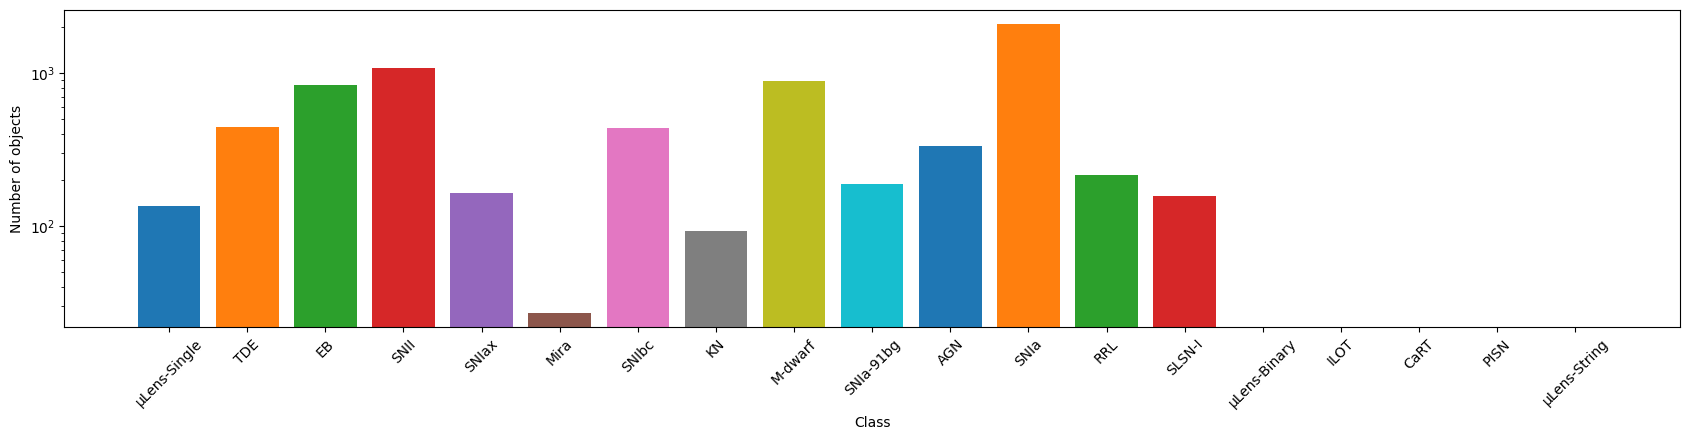

In [9]:
# compute counts per class

fig, ax = plt.subplots(figsize=(17, 4.5))

counts = train_df["label"].value_counts()

for i, j in CLASS_NAMES.items():
    ax.bar(j, counts.get(i, 0))

ax.set_yscale("log")
ax.set_xlabel("Class")
ax.set_ylabel("Number of objects")
ax.tick_params(axis="x", rotation=45)

plt.tight_layout()

*write your answer here*

**Problem 1b**

Write a function `plot_lightcurve` that plots the flux (with uncertainties) as a function of time for each band, using the colours in `BAND_COLORS`.

Use your function to plot one example light curve from each of these classes: SN Ia (coded in the dataframes as 90), SN II (42), KN (64), AGN (88), RR Lyrae (92), and Mira (53).

*Hint* – use `np.isclose` to select the observations in each band, because the wavelengths are floating-point numbers.

/tmp/ipykernel_13796/3012811761.py:34: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0, 0].legend(ncol=6, fontsize=8)


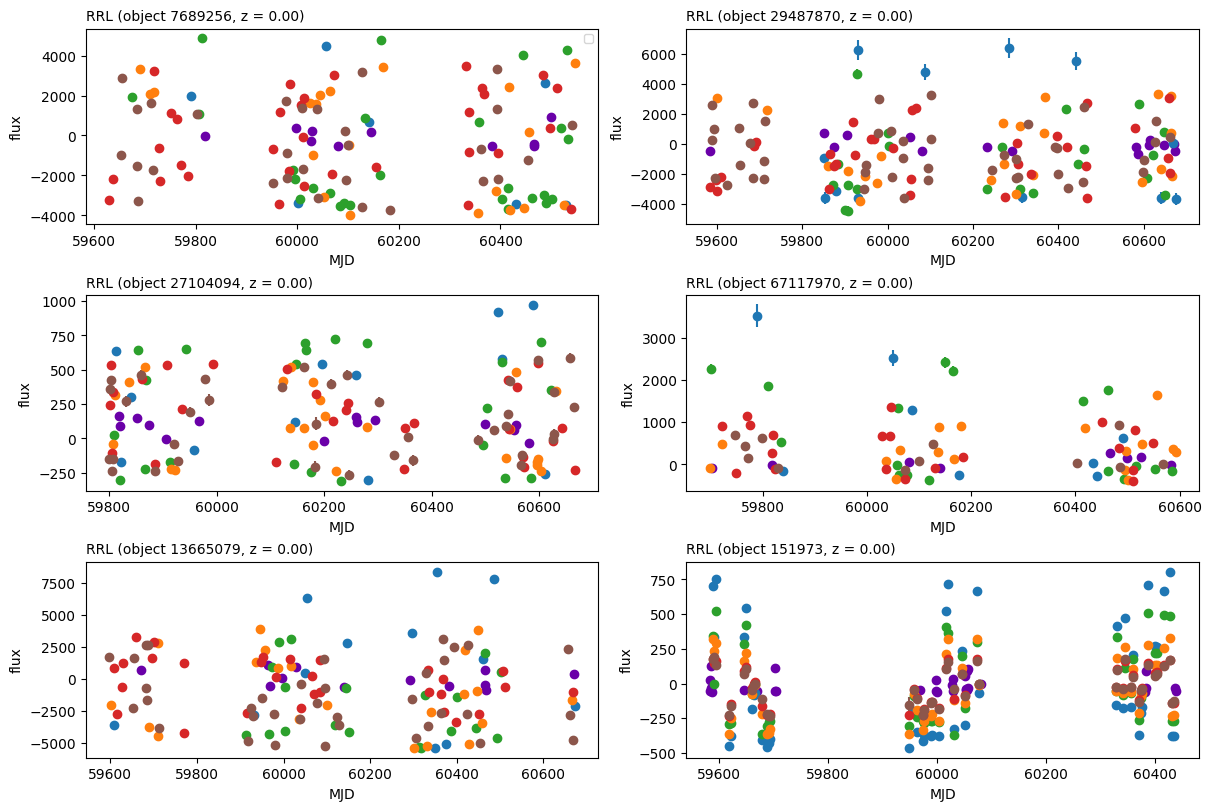

In [29]:
def plot_lightcurve(lc, ax=None):
    '''
    Plot a multi-band light curve

    Parameters
    ----------
    lc : dict
        output of `unpack_row`

    ax : matplotlib axis (optional)
        axis to draw on

    Returns
    -------
    ax : matplotlib axis
    '''
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 3))
    for b, wv in enumerate(BAND_WV):
        in_band = np.isclose(lc['wv'],wv) # get observations in band b
        # plot lightcurve fluxes with uncertainties (hint: use ax.errorbar)
        ax.errorbar(lc["t"][in_band], lc["flux"][in_band], lc["flux_err"][in_band], fmt="o", color=BAND_COLORS[b])
    ax.set_xlabel("MJD")
    ax.set_ylabel("flux")
    ax.set_title(f"{CLASS_NAMES[lc['label']]} (object {lc['object_id']}, z = {lc['redshift']:.2f})",
                 loc="left", fontsize=10)
    return ax


fig, axes = plt.subplots(3, 2, figsize=(12, 8), constrained_layout=True)
for ax, cls in zip(axes.flat, [90, 42, 64, 88, 92, 53]):
    lc = train_lcs[cls] # get a sample lightcurve for class cls
    plot_lightcurve(lc, ax)
axes[0, 0].legend(ncol=6, fontsize=8)

**Problem 1c** – *Worry about the data*

Before you build a classifier, compare the WFD and DDF light curves.

1. Plot histograms of the number of observations per object for WFD and DDF objects. What fraction of the objects in each survey reach the 300-observation limit of this data set?
2. Plot histograms of `hostgal_photoz` for non-galactic classes (`hostgal_photoz == 0`) and the other classes. Which classes are galactic?

Which properties of the data come from the astrophysics, and which come from the survey? Why can a classifier that uses survey properties (for example, the number of observations) fail on new data?

In [44]:
train_df.value_counts("label")

,count
label,
90,2082
42,1074
65,883
16,832
15,446
62,436
88,333
92,215
67,187


In [ ]:
n_obs = train_df.value_counts('object_id') # array of number of observations for each object in the dataset
ddf = train_df.value_counts("ddf_bool") # boolean array of whether each object is a ddf object

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
# histogram overlaying WFD and DDF distribution in number of observations
# CODE HERE
ax.hist()

# histogram overlaying `hostgal_photoz` for objects that have host galaxy photo-z > 0 (non-galactic)
# CODE HERE
fig.tight_layout()

SyntaxError: invalid syntax (2914031519.py, line 1)

*write your answer here*

## Problem 2) Gaussian-Process Models of Multi-Band Light Curves

Most ML algorithms need inputs with a fixed size and a fixed meaning for each element. Our light curves have different numbers of observations, at different times, in different bands. The first step of both avocado and SCONE is to fit a GP that is a function of both time *and* wavelength:

$$f(t, \lambda) \sim \text{GP}\big(0, k\big), \qquad k\big((t,\lambda), (t',\lambda')\big) = A^2 \left(1 + \sqrt{3}\,r\right) e^{-\sqrt{3}\,r}, \qquad r^2 = \frac{(t-t')^2}{\ell_t^2} + \frac{(\lambda-\lambda')^2}{\ell_\lambda^2}.$$

This is a 2D Matérn-3/2 kernel. Because the kernel couples nearby wavelengths, an observation in one band also constrains the model in the other bands. As in avocado, we fix $\ell_\lambda = 6000$ Å, and fit the amplitude $A$ and the time scale $\ell_t$ by maximising the marginal likelihood (you did this on Days 2 and 3):

$$-\ln L = \tfrac{1}{2}\,\mathbf{y}^\top K^{-1}\mathbf{y} + \tfrac{1}{2}\ln|K| + \tfrac{N}{2}\ln 2\pi, \qquad K = k(X, X) + \mathrm{diag}(\sigma_i^2).$$

When the GP is conditioned on the data, we can predict the flux (with an uncertainty) at *any* time and wavelength, and so build a regular representation of each light curve.

**Problem 2a**

Complete `matern32_kernel`, which returns the kernel for time separations `dt` and wavelength separations `dwv`. Then run the test in the cell below it.

In [ ]:
WV_SCALE = 6000.0  # wavelength length scale (Å), fixed as in avocado
SQRT3 = np.sqrt(3.0)


def matern32_kernel(dt, dwv, amp, ell_t, ell_wv=WV_SCALE):
    '''
    2D Matern-3/2 kernel in time and wavelength

    Parameters
    ----------
    dt : array-like
        time separations (d)

    dwv : array-like
        wavelength separations (Å), same shape as dt

    amp : float
        amplitude A (flux units)

    ell_t : float
        time length scale (d)

    ell_wv : float (default=WV_SCALE)
        wavelength length scale (Å)

    Returns
    -------
    k : array-like
        kernel values, same shape as dt
    '''
    r = # complete
    return # complete

In [ ]:
# k(0, 0) = A^2, and at r = 1 the kernel is A^2 (1 + sqrt(3)) exp(-sqrt(3))
assert np.isclose(matern32_kernel(0.0, 0.0, 2.0, 10.0), 4.0)
assert np.isclose(matern32_kernel(10.0, 0.0, 2.0, 10.0), 4 * (1 + np.sqrt(3)) * np.exp(-np.sqrt(3)))
assert np.isclose(matern32_kernel(0.0, 6000.0, 2.0, 10.0), 4 * (1 + np.sqrt(3)) * np.exp(-np.sqrt(3)))
print("matern32_kernel passes the tests")

The functions below fit the GP and make predictions. `neg_log_like` also returns the gradient of $-\ln L$ with respect to $(\ln A, \ln \ell_t)$, which makes the optimisation much faster than with numerical derivatives:

$$\frac{\partial (-\ln L)}{\partial \theta} = -\tfrac{1}{2}\,\mathrm{tr}\!\left[\left(\boldsymbol{\alpha}\boldsymbol{\alpha}^\top - K^{-1}\right)\frac{\partial K}{\partial\theta}\right], \qquad \boldsymbol{\alpha} = K^{-1}\mathbf{y}.$$

The cost of each likelihood evaluation grows as $N^3$, so `fit_gp` fits $A$ and $\ell_t$ on at most 120 observations (evenly spaced in time), and then conditions the GP on *all* of the observations. This matters for the DDF light curves, which have up to 300 observations.

Read the code, and make sure that you understand what each function does. You do not need to change it.

In [ ]:
def neg_log_like(theta, dt2, dwv2, y, var):
    '''
    Negative log marginal likelihood of the GP, and its gradient

    Parameters
    ----------
    theta : array-like
        (ln A, ln ell_t)

    dt2, dwv2 : array-like
        squared time and wavelength separations between all pairs of observations

    y : array-like
        flux measurements

    var : array-like
        flux variances (sigma_i^2)

    Returns
    -------
    nll : float
        -ln L

    grad : array-like
        d(-ln L)/d(theta)
    '''
    amp2, ell2 = np.exp(2 * theta[0]), np.exp(2 * theta[1])
    q = dt2 / ell2
    r = np.sqrt(q + dwv2 / WV_SCALE**2)
    e = np.exp(-SQRT3 * r)
    M = (1 + SQRT3 * r) * e
    K = amp2 * M
    K[np.diag_indices_from(K)] += var
    try:
        cf = cho_factor(K, lower=True, check_finite=False)
    except LinAlgError:
        return 1e25, np.zeros(2)
    alpha = cho_solve(cf, y, check_finite=False)
    nll = 0.5 * y @ alpha + np.log(np.diag(cf[0])).sum() + 0.5 * len(y) * np.log(2 * np.pi)
    W = np.outer(alpha, alpha) - cho_solve(cf, np.eye(len(y)), check_finite=False)
    dK_dlnA = 2 * amp2 * M
    dK_dlnell = 3 * amp2 * q * e
    grad = -0.5 * np.array([np.sum(W * dK_dlnA), np.sum(W * dK_dlnell)])
    return nll, grad


N_FIT_MAX = 120  # fit the hyperparameters on at most this many observations


def fit_gp(t, wv, flux, flux_err, ell_guess=20.0, n_fit_max=N_FIT_MAX):
    '''
    Fit A and ell_t by maximising the marginal likelihood (on at most n_fit_max observations,
    evenly spaced in time), then condition the GP on all of the data

    Returns
    -------
    gp : dict
        the data locations, best-fit hyperparameters, Cholesky factor L of K, and alpha = K^-1 y
    '''
    order = np.argsort(t)
    sub = order[np.linspace(0, len(t) - 1, min(len(t), n_fit_max)).astype(int)]
    dt2 = (t[sub, None] - t[None, sub])**2
    dwv2 = (wv[sub, None] - wv[None, sub])**2
    amp0 = max(np.max(np.abs(flux)), 1.0)
    x0 = np.log([amp0, ell_guess])
    bounds = [(np.log(amp0) - 5, np.log(amp0) + 3), (np.log(1.0), np.log(1000.0))]
    res = minimize(neg_log_like, x0, args=(dt2, dwv2, flux[sub], flux_err[sub]**2), jac=True,
                   method="L-BFGS-B", bounds=bounds)
    amp, ell = np.exp(res.x)
    K = matern32_kernel(t[:, None] - t[None, :], wv[:, None] - wv[None, :], amp, ell)
    K[np.diag_indices_from(K)] += flux_err**2
    L = np.linalg.cholesky(K)
    alpha = cho_solve((L, True), flux, check_finite=False)
    return dict(t=t, wv=wv, amp=amp, ell=ell, L=L, alpha=alpha, nll=res.fun)


def gp_predict(gp, t_new, wv_new, return_std=False):
    '''
    GP prediction (mean, and optionally standard deviation) at new times and wavelengths
    '''
    Ks = matern32_kernel(t_new[:, None] - gp["t"][None, :],
                         wv_new[:, None] - gp["wv"][None, :], gp["amp"], gp["ell"])
    mean = Ks @ gp["alpha"]
    if not return_std:
        return mean
    v = solve_triangular(gp["L"], Ks.T, lower=True, check_finite=False)
    var = gp["amp"]**2 - np.sum(v**2, axis=0)
    return mean, np.sqrt(np.clip(var, 0, None))

**Problem 2b**

Fit a GP to the SN Ia that you plotted in Problem 1b. Print the best-fit $A$ and $\ell_t$.

Then write a function `plot_gp` that plots the light curve (use `plot_lightcurve`) together with the GP mean and the $\pm1\sigma$ band in each of the 6 bands, on a regular time grid.

Do the same for the SN II and the RR Lyrae. Where is the GP uncertain? Does the GP model of the RR Lyrae make sense?

In [ ]:
def plot_gp(lc, gp, ax=None, pad=30):
    '''
    Plot a light curve and its GP model (mean and 1-sigma band) in each band
    '''
    ax = plot_lightcurve(lc, ax)
    t_grid = # use np.linspace to make a 1000-point grid from min t - pad to max t + pad
    for b, wv in enumerate(BAND_WV):
        mean, std = # complete
        # plot GP fit (use fill_between to show std region)
    return ax


fig, axes = plt.subplots(3, 1, figsize=(10, 9), constrained_layout=True)
for ax, cls in zip(axes, [90, 42, 92]):
    lc = # complete
    gp = # complete
    print(f"{CLASS_NAMES[cls]:5s}: A = {gp['amp']:9.1f}, ell_t = {gp['ell']:7.1f} d")
    plot_gp(lc, gp, ax)
axes[0].legend(ncol=6, fontsize=8)

*write your answer here*

**Problem 2c**

Fit GPs to 15 objects from each of these classes: SN Ia, SLSN-I, KN, AGN, and Mira. Plot the distribution of $\log_{10}\ell_t$ for each class (for example, with a strip plot or overlapping histograms).

Does the fitted time scale separate the classes? What else changes the observed time scale of an extragalactic transient?

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for i, cls in enumerate([90, 95, 64, 88, 53]):
    sample = # take 15 lightcurves from each class
    ells = # compute gp fits, take 'ell' from each
    ax.plot(np.log10(ells), i + rng.uniform(-0.15, 0.15, len(ells)), "o", alpha=0.7)
ax.set_yticks(range(5))
ax.set_yticklabels([CLASS_NAMES[c] for c in [90, 95, 64, 88, 53]])
ax.set_xlabel(r"$\log_{10}\,\ell_t$ (d)")
fig.tight_layout()

*write your answer here*

## Problem 3) Feature Engineering and Gradient-Boosted Trees (avocado)

avocado computes a few tens of features from the GP model and the data – for example the peak brightness, the colours at peak, the rise and decline times, and signal-to-noise statistics – and adds the host-galaxy photo-z. It then trains an ensemble of gradient-boosted decision trees (LightGBM).

The function `extract_features` below computes a smaller set of avocado-like features:

| feature(s) | description |
| :-- | :-- |
| `hostgal_photoz`, `hostgal_photoz_err` | host-galaxy photo-z and its uncertainty |
| `log_ell`, `log_amp` | best-fit GP hyperparameters ($\log_{10}$) |
| `log_peak_flux` | $\log_{10}$ of the peak of the GP flux summed over the 6 bands |
| `peak_frac_{u..y}` | fraction of the peak flux in each band (a measure of the colour at peak) |
| `rise_20`, `rise_50`, `fall_20`, `fall_50` | time (d) for the summed GP flux to rise from, and decline to, 20% or 50% of the peak (NaN if it never does) |
| `pos_width`, `neg_width` | integral of the positive (negative) summed GP flux, divided by the peak flux (d) |
| `total_s2n`, `frac_s2n_5`, `frac_s2n_m5` | total S/N of the light curve, and the fractions of observations with S/N $> 5$ and S/N $< -5$ |
| `time_width_s2n_5` | time between the first and the last observation with S/N $> 5$ |
| `ls_log_period`, `ls_power` | period and peak power of a Lomb-Scargle periodogram of the light curve (each band standardised). Only for Galactic objects (`hostgal_photoz == 0`), because all of the periodic classes in PLAsTiCC are Galactic; NaN otherwise |

The gradient-boosted trees in `scikit-learn` (`HistGradientBoostingClassifier`) handle `NaN` values directly, so we do not need to fill in missing features.

The same cell also defines `make_heatmap`, which we will use in Problem 4.

In [ ]:
def gp_grid(gp, t, dt=2.0, pad=30.0):
    '''GP mean in the 6 LSST bands on a regular time grid; returns the grid and an array of shape (6, n_time)'''
    t_grid = np.arange(t.min() - pad, t.max() + pad, dt)
    T, W = np.meshgrid(t_grid, BAND_WV)
    return t_grid, gp_predict(gp, T.ravel(), W.ravel()).reshape(W.shape)


def crossing_time(total, i_peak, frac, step, direction):
    '''Time (d) from the peak until `total` first drops below frac * peak, going backward (-1) or forward (+1)'''
    level = frac * total[i_peak]
    idx = np.arange(i_peak, -1, -1) if direction < 0 else np.arange(i_peak, len(total))
    below = np.nonzero(total[idx] < level)[0]
    return np.nan if len(below) == 0 else below[0] * step


def lomb_scargle_features(t, wv, flux, flux_err):
    '''log10(best period) and peak power of a Lomb-Scargle periodogram (periods > 0.2 d), with each band standardised'''
    y, dy = np.empty_like(flux), np.empty_like(flux_err)
    for w in np.unique(wv):
        m = wv == w
        s = np.std(flux[m]) if m.sum() > 1 else 1.0
        s = s if s > 0 else 1.0
        y[m] = (flux[m] - np.mean(flux[m])) / s
        dy[m] = flux_err[m] / s
    span = max(t.max() - t.min(), 1.0)
    freq, power = LombScargle(t, y, dy).autopower(minimum_frequency=1 / span,
                                                  maximum_frequency=5.0, samples_per_peak=3)
    i = np.argmax(power)
    return np.log10(1 / freq[i]), power[i]


def extract_features(lc, gp):
    '''
    Compute avocado-like features for one light curve

    Returns
    -------
    feats : dict
        feature name -> value

    t_peak : float
        time of the peak of the GP flux summed over the 6 bands
    '''
    t, f, e = lc["t"], lc["flux"], lc["flux_err"]
    t_grid, grid = gp_grid(gp, t)
    total = grid.sum(axis=0)
    i_peak = int(np.argmax(total))
    f_peak = total[i_peak]
    step = t_grid[1] - t_grid[0]

    feats = dict(hostgal_photoz=lc["photoz"], hostgal_photoz_err=lc["photoz_err"],
                 log_ell=np.log10(gp["ell"]), log_amp=np.log10(gp["amp"]))
    shape_names = (["log_peak_flux"] + [f"peak_frac_{b}" for b in BANDS]
                   + ["rise_20", "fall_20", "rise_50", "fall_50", "pos_width", "neg_width"])
    if f_peak > 0:
        feats["log_peak_flux"] = np.log10(f_peak)
        for b, name in enumerate(BANDS):
            feats[f"peak_frac_{name}"] = grid[b, i_peak] / f_peak
        for frac in (0.2, 0.5):
            feats[f"rise_{int(frac * 100)}"] = crossing_time(total, i_peak, frac, step, -1)
            feats[f"fall_{int(frac * 100)}"] = crossing_time(total, i_peak, frac, step, +1)
        feats["pos_width"] = np.clip(total, 0, None).sum() * step / f_peak
        feats["neg_width"] = np.clip(-total, 0, None).sum() * step / f_peak
    else:  # no positive signal: the shape features are not defined
        feats.update({name: np.nan for name in shape_names})

    s2n = f / e
    feats["total_s2n"] = np.sqrt(np.sum(s2n**2))
    feats["frac_s2n_5"] = np.mean(s2n > 5)
    feats["frac_s2n_m5"] = np.mean(s2n < -5)
    detected = t[s2n > 5]
    feats["time_width_s2n_5"] = detected.max() - detected.min() if len(detected) > 1 else np.nan
    if lc["photoz"] == 0:  # Galactic: could be a periodic variable
        feats["ls_log_period"], feats["ls_power"] = lomb_scargle_features(t, lc["wv"], f, e)
    else:
        feats["ls_log_period"], feats["ls_power"] = np.nan, np.nan
    return feats, t_grid[i_peak]


HM_WV = np.linspace(3000, 10100, 32)    # heatmap wavelengths (Å)
HM_DT = np.arange(-60, 120, 2.0)        # heatmap times (d), relative to t_peak
HM_WV_STD = np.linspace(3000, 10100, 8) # the GP std varies slowly with wavelength: compute it on 8 rows


def make_heatmap(gp, t_peak):
    '''
    SCONE-like heatmap: GP mean and standard deviation on a (wavelength x time) grid around the peak,
    both divided by the maximum |mean|. Returns an array of shape (2, 32, 90).
    '''
    T, W = np.meshgrid(t_peak + HM_DT, HM_WV)
    mean = gp_predict(gp, T.ravel(), W.ravel()).reshape(W.shape)
    Tc, Wc = np.meshgrid(t_peak + HM_DT, HM_WV_STD)
    std_coarse = gp_predict(gp, Tc.ravel(), Wc.ravel(), return_std=True)[1].reshape(Wc.shape)
    std = np.array([np.interp(HM_WV, HM_WV_STD, column) for column in std_coarse.T]).T
    norm = max(np.max(np.abs(mean)), 1e-6)
    return np.stack([mean / norm, std / norm]).astype(np.float32)


def process(lc):
    '''Fit the GP, then return (features, heatmap) for one light curve'''
    try:
        gp = fit_gp(lc["t"], lc["wv"], lc["flux"], lc["flux_err"])
        feats, t_peak = extract_features(lc, gp)
        return feats, make_heatmap(gp, t_peak)
    except Exception:  # very rare numerical failures: keep the object, with missing features
        return dict(hostgal_photoz=lc["photoz"], hostgal_photoz_err=lc["photoz_err"]), \
            np.zeros((2, len(HM_WV), len(HM_DT)), dtype=np.float32)

**Problem 3a**

Run `process` on the SN Ia from Problem 1b, and print the features. Do the values make sense, given your plot of the light curve and the GP?

In [ ]:
lc = # complete
feats, heatmap = # run process
pd.Series(feats).round(3)

The next cell runs `process` on every object in the training and validation sets, using all of the CPU cores (with `joblib`). This takes several minutes in Colab, so **start it now, and read ahead while it runs**.

If precomputed results are available on Hugging Face, the cell downloads them instead (in a few seconds). Set `USE_PRECOMPUTED = False` to compute everything yourself.

The results are saved to files. If you restart the notebook, the cell reads the files instead of recomputing (delete the files if you change `process`).

In [ ]:
def process_all(lcs, name):
    '''Features (DataFrame) and heatmaps (array) for a list of light curves, with a cache on disk'''
    cache = f"gp_products_{name}.npz"
    if not os.path.exists(cache):
        # to save time we're going to download Helen's pre-computed GP fits
        os.symlink(hf_hub_download(REPO, f"data/{name}/{cache}", repo_type="dataset"), cache)
        print(f"{name}: using precomputed results")

    else:
        os.path.exists(cache):
        d = np.load(cache)
        feats = pd.DataFrame(d["features"], columns=d["columns"])
        feats[["object_id", "label"]] = feats[["object_id", "label"]].astype(np.int64)
        return feats, d["heatmaps"].astype(np.float32)
    t0 = time.time()
    out = Parallel(n_jobs=-1, verbose=1)(delayed(process)(lc) for lc in lcs)
    feats = pd.DataFrame([o[0] for o in out])
    feats.insert(0, "object_id", [lc["object_id"] for lc in lcs])
    feats.insert(1, "label", [lc["label"] for lc in lcs])
    heatmaps = np.stack([o[1] for o in out])
    np.savez_compressed(cache, features=feats.values.astype(float),
                        columns=np.array(feats.columns, dtype=str), heatmaps=heatmaps.astype(np.float16))
    print(f"{name}: {len(lcs)} objects in {time.time() - t0:.0f} s")
    return feats, heatmaps


train_feats, train_hm = process_all(train_lcs, "train")
val_feats, val_hm = process_all(val_lcs, "validation")

FEATURES = [c for c in train_feats.columns if c not in ("object_id", "label")]
CLASSES = np.sort(train_feats["label"].unique())
print(f"{len(FEATURES)} features, {len(CLASSES)} classes; heatmaps: {train_hm.shape}")

To evaluate a classifier on imbalanced classes we will use two metrics that weight every class equally:

* the **balanced accuracy**: the mean, over the classes, of the fraction of each class that is classified correctly;
* the **flat-weighted log loss** (used by avocado): the mean, over the classes, of $-\langle \ln p_{\rm true} \rangle$, where $p_{\rm true}$ is the probability that the classifier gives to the true class. Unlike the accuracy, this metric also rewards *well-calibrated* probabilities. A classifier that always predicts equal probabilities for the 14 classes has a log loss of $\ln 14 \approx 2.64$.

In [ ]:
def flat_log_loss(y, prob, classes):
    '''
    Log loss with equal weight for each class

    Parameters
    ----------
    y : array-like
        true labels (PLAsTiCC IDs)

    prob : array-like, shape (n_objects, n_classes)
        predicted probabilities, with columns in the order of `classes`

    classes : array-like
        PLAsTiCC IDs of the columns of `prob`
    '''
    idx = np.searchsorted(classes, y)
    log_p = np.log(np.clip(prob[np.arange(len(y)), idx], 1e-15, 1))
    return -np.mean([log_p[idx == k].mean() for k in np.unique(idx)])


def make_classifier():
    '''Gradient-boosted trees with class weights and early stopping'''
    return HistGradientBoostingClassifier(learning_rate=0.05, max_iter=1000, max_leaf_nodes=15,
                                          l2_regularization=1.0, early_stopping=True,
                                          validation_fraction=0.15, n_iter_no_change=30,
                                          class_weight="balanced", random_state=0)


def evaluate(name, y, prob, classes=CLASSES):
    '''Print the balanced accuracy and the flat-weighted log loss'''
    pred = classes[np.argmax(prob, axis=1)]
    print(f"{name:>20s}: balanced accuracy = {balanced_accuracy_score(y, pred):.3f}, "
          f"flat log loss = {flat_log_loss(y, prob, classes):.3f}")

**Problem 3b**

First, build a baseline. Train a classifier (use `make_classifier()`) on the training set with only three features that do not need a GP: `hostgal_photoz`, `hostgal_photoz_err`, and `total_s2n`. Evaluate it on the validation set with `evaluate`.

*Hint* – `predict_proba` returns the probabilities in the order of `clf.classes_`, which is the same as `CLASSES`.

In [ ]:
BASELINE = ["hostgal_photoz", "hostgal_photoz_err", "total_s2n"]

clf_base = # classifier
prob_base = # predicted probs from classifier
evaluate("baseline", val_feats["label"], prob_base)

**Problem 3c**

Now train a classifier with all of the `FEATURES`, and evaluate it. How much do the GP features help?

Plot the confusion matrix, normalised by the true class (use `ConfusionMatrixDisplay.from_predictions` with `normalize="true"`). Which classes are confused with each other? Is there a physical reason?

In [ ]:
clf_trees = # classifier
prob_trees = # predicted probs from classifier
evaluate("baseline", val_feats["label"], prob_base)
evaluate("all features", val_feats["label"], prob_trees)

NAMES = [CLASS_NAMES[c] for c in CLASSES]
fig, ax = plt.subplots(figsize=(8, 7))
# confusion matrix plotting code
ax.set_title("gradient-boosted trees (validation)")
fig.tight_layout()

*write your answer here*

**Problem 3d**

Which features matter? Calculate the permutation importance of each feature on the validation set (use `permutation_importance` with `scoring="balanced_accuracy"` and `n_repeats=5`), and plot the 12 most important features.

Which of the important features describe the astrophysics, and which describe the survey?

In [ ]:
pi = # permutation importance

fig, ax = plt.subplots(figsize=(6, 4.5))
# horizontal bar plot of top 12 most important features
ax.set_xlabel("decrease in balanced accuracy when the feature is shuffled")
fig.tight_layout()

*write your answer here*

**Problem 3e** – *Challenge* (come back to this after P4 if you have time!)

Add a new feature, and find out if it improves the classifier. Some ideas:

* *rest-frame* time scales: divide the rise and decline times by $(1 + \texttt{hostgal\_photoz})$;
* the colour at a fixed time after the peak (for example $+20$ d), which separates some SN subtypes;
* a feature from Day 1 or Day 2 (for example, a structure-function or autocorrelation time scale).

*Hint* – calculate the new features in a separate function, and join them to `train_feats` and `val_feats` with `object_id`, so that you do not have to recompute everything.

In [ ]:
# complete

## Problem 4) A CNN on GP Heatmaps (SCONE)

Instead of designing features, SCONE evaluates the GP on a regular grid of wavelength and time, and gives the resulting 2D "heatmap" to a CNN. Our heatmaps have 32 wavelengths (3000–10100 Å) and 90 times (2-day steps, from 60 d before to 120 d after the GP peak), and two channels: the GP mean and the GP standard deviation (both divided by the maximum of the mean). The uncertainty channel tells the network where the GP has no data.

Because the heatmap is a regular image, we can use the same type of CNN that you used for images in Session 25.

**Problem 4a**

Plot the two channels of the heatmaps of an SN Ia, an SN II, and an AGN from the training set (use `imshow` with `aspect="auto"`, `origin="lower"`, and an `extent` in days and Å).

What differences between the classes can you see? What information did the normalisation remove?

In [ ]:
def plot_heatmap(hm, axes):
    extent = [HM_DT[0], HM_DT[-1], HM_WV[0], HM_WV[-1]]
    # plot GP mean on axes[0]
    # plot GP std on axes[1]
    axes[0].set_ylabel("wavelength (Å)")


fig, axes = plt.subplots(3, 2, figsize=(10, 7), sharex=True, sharey=True, constrained_layout=True)
for row, cls in zip(axes, [90, 42, 88]):
    i = # complete
    plot_heatmap(train_hm[i], row)
    row[0].set_title(f"{CLASS_NAMES[cls]}: GP mean", loc="left", fontsize=10)
    row[1].set_title(f"{CLASS_NAMES[cls]}: GP std", loc="left", fontsize=10)
for ax in axes[-1]:
    ax.set_xlabel("days from peak")

*write your answer here*

The next cell prepares the data for PyTorch: it converts the labels to indices $0, \ldots, 13$, computes class weights for the loss, and makes the `DataLoader`s. It also defines `run_epoch` (one pass through a data set, with or without training) and `predict_proba`.

In [ ]:
y_train = np.searchsorted(CLASSES, train_feats["label"].values)
y_val = np.searchsorted(CLASSES, val_feats["label"].values)

class_counts = np.bincount(y_train, minlength=len(CLASSES))
class_weights = torch.tensor(len(y_train) / (len(CLASSES) * class_counts), dtype=torch.float32, device=device)

train_loader = DataLoader(TensorDataset(torch.from_numpy(train_hm), torch.from_numpy(y_train)),
                          batch_size=64, shuffle=True)
val_loader = DataLoader(TensorDataset(torch.from_numpy(val_hm), torch.from_numpy(y_val)),
                        batch_size=256)


def run_epoch(model, loader, loss_fn, optimizer=None):
    '''One pass through `loader`; trains the model if an optimizer is given. Returns the mean loss.'''
    model.train(optimizer is not None)
    total, n = 0.0, 0
    with torch.set_grad_enabled(optimizer is not None):
        for *inputs, yb in loader:
            inputs, yb = [x.to(device) for x in inputs], yb.to(device)
            loss = loss_fn(model(*inputs), yb)
            if optimizer is not None:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total += loss.item() * len(yb)
            n += len(yb)
    return total / n


def predict_proba(model, *arrays, batch_size=512):
    '''Class probabilities (numpy array) for the inputs in `arrays`'''
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(arrays[0]), batch_size):
            inputs = [torch.as_tensor(a[i:i + batch_size]).to(device) for a in arrays]
            out.append(torch.softmax(model(*inputs), dim=1).cpu().numpy())
    return np.concatenate(out)

Here is a CNN class, `HeatmapCNN`, that takes a batch of heatmaps with shape `(batch, 2, 32, 90)` and returns logits with shape `(batch, 14)`.

We keep the network small: 2 or 3 convolutional blocks (`Conv2d` $\rightarrow$ `BatchNorm2d` $\rightarrow$ `ReLU` $\rightarrow$ `MaxPool2d`), then a small fully connected head with dropout. One epoch on a CPU should take less than about 10 s.

*Hint* – `nn.AdaptiveAvgPool2d((4, 8))` before `nn.Flatten()` gives a fixed number of features, whatever the size of the input. Give `forward` an optional second argument `extra=None` (ignored for now); you will use it in Problem 4e.

In [ ]:
class HeatmapCNN(nn.Module):
    def __init__(self, n_classes, n_extra=0):
        super().__init__()
        self.conv = nn.Sequential(
            # implement the following network:
            # 3 blocks with output channels 16, 32, 64. each block has:

            # Conv2d: kernel size 3, padding 1. Input channels = previous block’s output (first block: 2).
            # BatchNorm2d
            # ReLU
            # MaxPool2d(2): blocks 1 and 2 only. Skip it in block 3.
            #
            # at the end of block 3 add:
            # AdaptiveAvgPool2d to size (4, 8)
            # Flatten
        )
        self.head = nn.Sequential(
            nn.Dropout(0.3), nn.Linear(64 * 4 * 8 + n_extra, 64), nn.ReLU(),
            nn.Dropout(0.3), nn.Linear(64, n_classes))

    def forward(self, x, extra=None):
        h = self.conv(x)
        if extra is not None:
            h = torch.cat([h, extra], dim=1)
        return self.head(h)


cnn = HeatmapCNN(len(CLASSES)).to(device)
print(cnn)
print(f"{sum(p.numel() for p in cnn.parameters()):,} trainable parameters")
print("output shape:", cnn(torch.from_numpy(train_hm[:4]).to(device)).shape)

**Problem 4c**

Train the CNN for 25 epochs with the Adam optimiser (learning rate $10^{-3}$, weight decay $10^{-4}$, `torch.optim.Adam`) and a cross-entropy loss (`nn.CrossEntropyLoss`) that uses `class_weights`. After each epoch, record the training and validation losses, and keep a copy of the model with the lowest validation loss (*early stopping*).

Plot the two loss curves. Is the network over-fitting?

In [ ]:
def train_model(model, train_loader, val_loader, n_epochs=25, lr=1e-3):
    '''Train with Adam and a class-weighted loss; returns the best model (lowest validation loss) and the history'''
    loss_fn = # complete
    optimizer = # complete
    history, best = {"train": [], "val": []}, (np.inf, None)
    for epoch in range(n_epochs):
        t0 = time.time()
        history["train"].append(# record training loss
        history["val"].append(# record validation loss
        if history["val"][-1] < best[0]:
            best = (history["val"][-1], copy.deepcopy(model.state_dict()))
        print(f"epoch {epoch + 1:2d}: train loss {history['train'][-1]:.3f}, "
              f"val loss {history['val'][-1]:.3f} ({time.time() - t0:.1f} s)")
    model.load_state_dict(best[1])
    return model, history


cnn, history = train_model(cnn, train_loader, val_loader)

fig, ax = plt.subplots(figsize=(6, 3.5))
# plot training and validation loss curves
ax.set_xlabel("epoch")
ax.set_ylabel("class-weighted cross-entropy")
fig.tight_layout()

**Problem 4d**

Evaluate the CNN on the validation set with `evaluate`, and plot its confusion matrix next to the confusion matrix of the trees.

For which classes is each model better? Why might the CNN have problems with the periodic variables? Finally, evaluate the average of the two sets of probabilities (a simple *ensemble*).

In [ ]:
prob_cnn = # (hint: predict_proba)
evaluate("trees", val_feats["label"], prob_trees)
evaluate("CNN", val_feats["label"], prob_cnn)
evaluate("trees + CNN", val_feats["label"], # ensemble of tree and CNN

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
# plot confusion matrix of tree and CNN
fig.tight_layout()

*write your answer here*

**Problem 4e** – *Challenge*

Make a *hybrid* model: give the host photo-z (and its uncertainty) to the CNN as the `extra` input, which `HeatmapCNN` concatenates with the convolutional features before the fully connected head. Does the extra information close the gap with the trees?

*Hint* – make new `DataLoader`s from `TensorDataset(heatmaps, extra, labels)`; `run_epoch` and `predict_proba` already accept more than one input.

In [ ]:
# complete

## References

* Boone, K. 2019, AJ, 158, 257 – *avocado*
* Qu, H., Sako, M., Möller, A., & Doux, C. 2021, AJ, 162, 67 – *SCONE*
* Kessler, R., et al. 2019, PASP, 131, 094501 – models and simulations for PLAsTiCC
* The PLAsTiCC team 2018, arXiv:1810.00001 – the PLAsTiCC data release
* Hložek, R., et al. 2023, ApJS (arXiv:2012.12392) – results of PLAsTiCC
* Qu, H., & Sako, M. 2022, AJ, 163, 57 – early-time classification with SCONE
* Rasmussen, C. E., & Williams, C. K. I. 2006, *Gaussian Processes for Machine Learning* (MIT Press)